# Laboratório — perceptron: treinamento, limites e comparação com o Adaline
**Aprendizado de Máquina (PEPAPRM) · IFSP Presidente Epitácio**

Demonstração guiada do laboratório. O perceptron é escrito do zero em NumPy, treinado época a época nas portas lógicas, em dados separáveis e em dados sobrepostos, e comparado com o Adaline e com a Iris. Nenhum arquivo de dados é necessário.

In [1]:
import sys
import warnings

import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")                      # no notebook as figuras aparecem na tela
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris, make_blobs
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Perceptron as PerceptronSklearn
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEMENTE = 42
SEMENTE_DEMO = 7                           # a demonstracao usa outros sorteios de dados que os exercicios
AZUL, VERMELHO, VERDE, CINZA, LARANJA = "#1F3864", "#C0392B", "#2E8B57", "#7F8C8D", "#E67E22"
pd.set_option("display.width", 110)


def secao(n, titulo):
    print()
    print("=" * 70)
    print(f"PASSO {n} - {titulo}")
    print("=" * 70)


def salva(fig, nome):
    fig.savefig(nome, dpi=150, bbox_inches="tight")
    if "ipykernel" in sys.modules:
        plt.show()
    else:
        plt.close(fig)
    print("figura salva em", nome)


X_PORTAS = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
PORTAS = {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "NAND": [1, 1, 1, 0],
          "NOR": [1, 0, 0, 0], "XOR": [0, 1, 1, 0]}


def dados_separaveis(n=100, semente=SEMENTE):
    """Duas classes separaveis pela reta x1 = x2, com uma faixa vazia (margem) em volta dela."""
    rng = np.random.default_rng(semente)
    X = rng.normal(size=(1500, 2)) * 1.5 + np.array([1.5, 1.5])
    dist = (X[:, 0] - X[:, 1]) / np.sqrt(2)
    X = X[np.abs(dist) > 0.4][:n]
    return X, (X[:, 0] - X[:, 1] > 0).astype(int)


def dados_sobrepostos(semente=SEMENTE):
    X, t = make_blobs(n_samples=300, centers=[(-1, -1), (1, 1)], cluster_std=1.6, random_state=semente)
    return train_test_split(X, t, test_size=0.3, random_state=semente, stratify=t)

## Passo 1 — o perceptron em NumPy
A classe tem três ideias: `fit` percorre os exemplos e corrige **só quando erra**, `z` calcula a soma ponderada (funciona para um vetor ou para um lote) e `predict` aplica o degrau. O treino guarda os erros de cada época e os pesos ao fim dela, para podermos acompanhar o que acontece. Conferimos com o AND feito à mão na aula de conceitos.

In [2]:
class Perceptron:
    def __init__(self, eta=1.0, max_epocas=100, embaralhar=False, semente=SEMENTE, w0=None, b0=0.0):
        self.eta, self.max_epocas, self.embaralhar, self.semente = eta, max_epocas, embaralhar, semente
        self.w0, self.b0 = w0, b0

    def z(self, X):                                    # soma ponderada + vies; X: (d,) ou (n, d)
        return np.asarray(X, dtype=float) @ self.w + self.b

    def predict(self, X):
        return (self.z(X) >= 0).astype(int)

    def score(self, X, t):
        return float(np.mean(self.predict(X) == np.asarray(t)))

    def fit(self, X, t):
        X, t = np.asarray(X, dtype=float), np.asarray(t, dtype=int)
        n, d = X.shape
        rng = np.random.default_rng(self.semente)
        self.w = np.zeros(d) if self.w0 is None else np.array(self.w0, dtype=float)
        self.b = float(self.b0)
        self.erros_, self.historico_ = [], []
        for _ in range(self.max_epocas):
            ordem = rng.permutation(n) if self.embaralhar else np.arange(n)
            erros = 0
            for i in ordem:
                e = t[i] - (1 if X[i] @ self.w + self.b >= 0 else 0)     # erro: -1, 0 ou +1
                if e != 0:                                                # so corrige se errou
                    self.w = self.w + self.eta * e * X[i]
                    self.b = self.b + self.eta * e
                    erros += 1
            self.erros_.append(erros)
            self.historico_.append((self.w.copy(), self.b))
            if erros == 0:
                break
        self.convergiu_ = self.erros_[-1] == 0
        return self


secao(1, "O PERCEPTRON CONFERIDO COM O EXEMPLO FEITO A MAO")
m = Perceptron(eta=1.0).fit(X_PORTAS, PORTAS["AND"])
print("AND  erros por epoca:", m.erros_, " w =", m.w, " b =", m.b)
assert m.erros_ == [2, 3, 3, 2, 1, 0] and np.allclose(m.w, [2, 1]) and m.b == -3
print("  confere com a apostila de conceitos: erros 2, 3, 3, 2, 1, 0; w = (2; 1); b = -3")
for nome in ("OR", "NOR"):
    m = Perceptron(eta=1.0).fit(X_PORTAS, PORTAS[nome])
    print(f"{nome:>3}  erros por epoca:", m.erros_, " w =", m.w, " b =", m.b)


PASSO 1 - O PERCEPTRON CONFERIDO COM O EXEMPLO FEITO A MAO
AND  erros por epoca: [2, 3, 3, 2, 1, 0]  w = [2. 1.]  b = -3.0
  confere com a apostila de conceitos: erros 2, 3, 3, 2, 1, 0; w = (2; 1); b = -3
 OR  erros por epoca: [2, 2, 1, 0]  w = [1. 1.]  b = -1.0
NOR  erros por epoca: [1, 2, 1, 0]  w = [-1. -1.]  b = 0.0


## Passo 2 — portas lógicas, o XOR e a taxa de aprendizado
Cinco portas com o mesmo código. As separáveis convergem; o XOR não. No XOR os pesos **voltam ao mesmo valor ao fim de cada época**: o treino gira em ciclo. Depois, o AND com quatro taxas de aprendizado: com pesos iniciais nulos, η só reescala os pesos, **exceto** quando o arredondamento de 0,1 decide de outro modo um empate z = 0.

In [3]:
secao(2, "PORTAS LOGICAS, XOR E TAXA DE APRENDIZADO")
linhas, modelos = [], {}
for nome, t in PORTAS.items():
    m = Perceptron(eta=1.0, max_epocas=50).fit(X_PORTAS, t)
    modelos[nome] = m
    linhas.append({"porta": nome, "convergiu": m.convergiu_, "epocas": len(m.erros_),
                   "w": tuple(m.w), "b": m.b})
print(pd.DataFrame(linhas).to_string(index=False))

xor = modelos["XOR"]
print("\nXOR  erros nas 10 primeiras epocas:", xor.erros_[:10])
distintos = {(tuple(float(v) for v in w), float(b)) for w, b in xor.historico_[2:]}
print("XOR  pares (w, b) distintos nos fins de epoca 3 a 50:", len(distintos), distintos)

print()
m1 = Perceptron(eta=1.0).fit(X_PORTAS, PORTAS["AND"])
pesos1 = np.r_[m1.w, m1.b]
for eta in (1.0, 0.5, 0.25, 0.1):
    m = Perceptron(eta=eta).fit(X_PORTAS, PORTAS["AND"])
    prop = np.allclose(np.r_[m.w, m.b] / eta, pesos1)
    print(f"AND  eta = {eta:<5} erros: {m.erros_}  w = {m.w}  b = {m.b:+.2f}  (w, b)/eta igual? {prop}")
print("\neta = 0.1: o empate z = 0 em (1, 0) e decidido pelo arredondamento de 0.1 em binario.")


PASSO 2 - PORTAS LOGICAS, XOR E TAXA DE APRENDIZADO
porta  convergiu  epocas            w    b
  AND       True       6   (2.0, 1.0) -3.0
   OR       True       4   (1.0, 1.0) -1.0
 NAND       True       6 (-2.0, -1.0)  2.0
  NOR       True       4 (-1.0, -1.0)  0.0
  XOR      False      50  (-1.0, 0.0)  0.0

XOR  erros nas 10 primeiras epocas: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4]
XOR  pares (w, b) distintos nos fins de epoca 3 a 50: 1 {((-1.0, 0.0), 0.0)}

AND  eta = 1.0   erros: [2, 3, 3, 2, 1, 0]  w = [2. 1.]  b = -3.00  (w, b)/eta igual? True
AND  eta = 0.5   erros: [2, 3, 3, 2, 1, 0]  w = [1.  0.5]  b = -1.50  (w, b)/eta igual? True
AND  eta = 0.25  erros: [2, 3, 3, 2, 1, 0]  w = [0.5  0.25]  b = -0.75  (w, b)/eta igual? True
AND  eta = 0.1   erros: [2, 3, 3, 0]  w = [0.2 0.1]  b = -0.20  (w, b)/eta igual? False

eta = 0.1: o empate z = 0 em (1, 0) e decidido pelo arredondamento de 0.1 em binario.


## Passo 3 — dados separáveis: a fronteira se move e o teorema
Cem pontos separáveis por x₁ = x₂, com uma faixa vazia em volta da reta (margem ≥ 0,4). A figura mostra a fronteira ao fim de cada época. Depois conferimos o **limite de erros** do teorema de convergência, (R/γ)², usando a própria reta x₁ = x₂ como separador.


PASSO 3 - DADOS SEPARAVEIS: A FRONTEIRA SE MOVE
exemplos: 100  erros por epoca: [7, 0]  total de correcoes: 7
w = [ 4.858 -4.909]  b = -1.0  acuracia no treino: 1.0
gamma = 0.403   R = 5.791   limite (R/gamma)^2 = 206.8   correcoes reais = 7


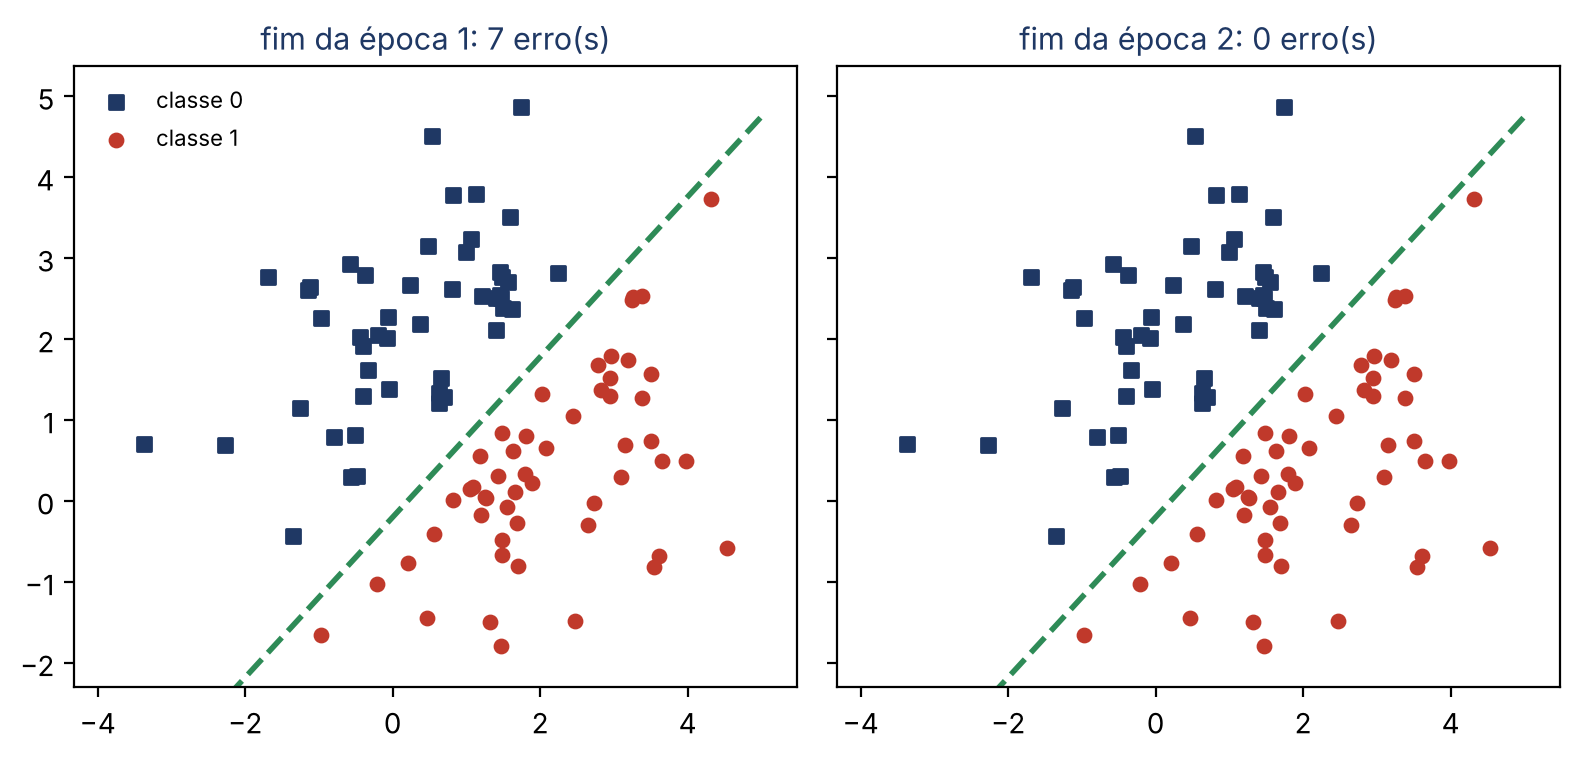

figura salva em lab_fronteira_epocas.png


In [4]:
secao(3, "DADOS SEPARAVEIS: A FRONTEIRA SE MOVE")
X3, t3 = dados_separaveis(semente=SEMENTE_DEMO)
m3 = Perceptron(eta=1.0).fit(X3, t3)
total = sum(m3.erros_)
print("exemplos:", len(X3), " erros por epoca:", m3.erros_, " total de correcoes:", total)
print("w =", m3.w.round(3), " b =", round(m3.b, 3), " acuracia no treino:", m3.score(X3, t3))

X_aum = np.c_[X3, np.ones(len(X3))]
w_star = np.array([1.0, -1.0, 0.0]) / np.sqrt(2)
gamma = ((2 * t3 - 1) * (X_aum @ w_star)).min()
R = np.linalg.norm(X_aum, axis=1).max()
print(f"gamma = {gamma:.3f}   R = {R:.3f}   limite (R/gamma)^2 = {(R / gamma) ** 2:.1f}   correcoes reais = {total}")
assert total <= (R / gamma) ** 2

epocas_fig = sorted({0, 1, len(m3.historico_) - 1})      # sem painel repetido se o treino acabar cedo
fig, axs = plt.subplots(1, len(epocas_fig), figsize=(4 * len(epocas_fig), 3.9), sharex=True, sharey=True)
xs = np.linspace(X3[:, 0].min() - 0.5, X3[:, 0].max() + 0.5, 200)
for ax, k in zip(axs, epocas_fig):
    w, b = m3.historico_[k]
    ax.scatter(*X3[t3 == 0].T, c=AZUL, marker="s", s=22, label="classe 0")
    ax.scatter(*X3[t3 == 1].T, c=VERMELHO, marker="o", s=22, label="classe 1")
    ax.plot(xs, -(w[0] * xs + b) / w[1], "--", c=VERDE, lw=2)
    ax.set_ylim(X3[:, 1].min() - 0.5, X3[:, 1].max() + 0.5)
    ax.set_title(f"fim da época {k + 1}: {m3.erros_[k]} erro(s)", color=AZUL, fontsize=11)
axs[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
salva(fig, "lab_fronteira_epocas.png")

## Passo 4 — dados sobrepostos e o algoritmo do bolso
Quando as classes se sobrepõem, não existe reta com zero erros: o perceptron **nunca converge** e os pesos da última época não são os melhores. O **bolso** guarda, depois de cada correção, o par (w, b) com menos erros no treino.


PASSO 4 - DADOS SOBREPOSTOS E O ALGORITMO DO BOLSO
convergiu? False  erros nas 5 ultimas epocas: [54, 54, 60, 58, 56]  menor: 47
pesos finais   treino: 0.800   teste: 0.800
bolso: 39 erros no treino   treino: 0.814   teste: 0.756
referencia (regressao logistica) no teste: 0.800


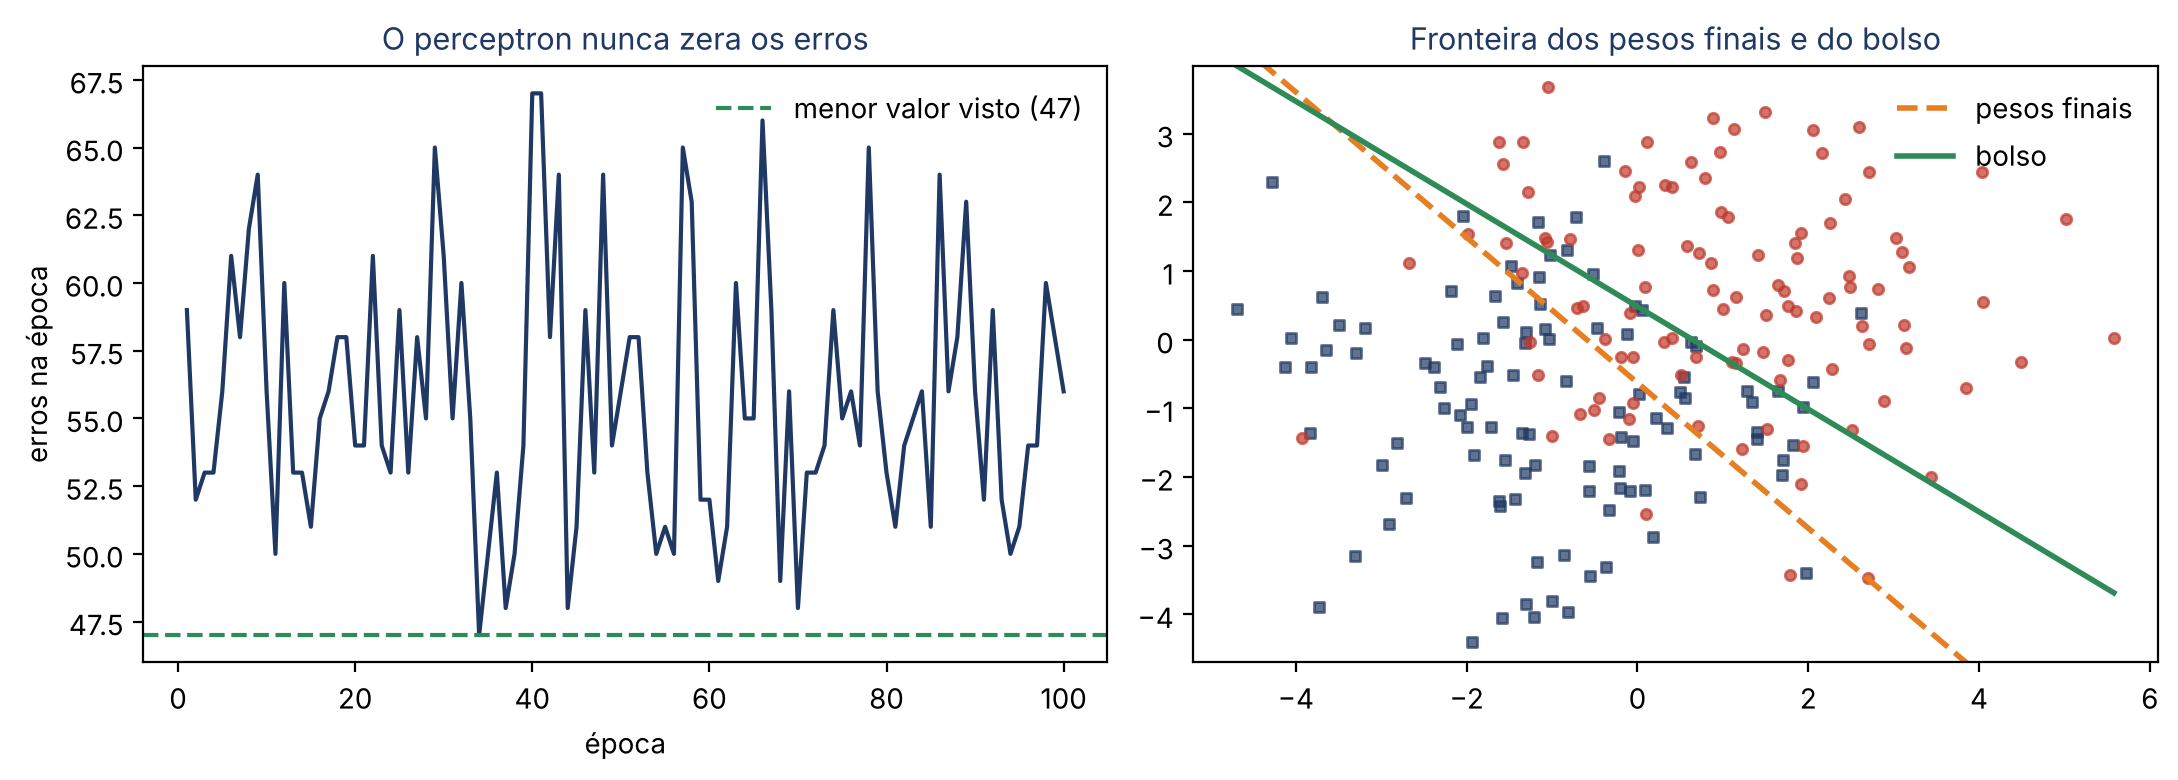

figura salva em lab_nao_separavel.png


In [5]:
def perceptron_bolso(X, t, eta=1.0, max_epocas=100, semente=SEMENTE):
    """Perceptron que guarda no bolso o (w, b) com menos erros no TREINO."""
    X, t = np.asarray(X, dtype=float), np.asarray(t, dtype=int)
    rng = np.random.default_rng(semente)
    w, b = np.zeros(X.shape[1]), 0.0
    melhor_w, melhor_b = w.copy(), b
    melhor_erros = int(np.sum((X @ w + b >= 0).astype(int) != t))
    for _ in range(max_epocas):
        for i in rng.permutation(len(X)):
            e = t[i] - (1 if X[i] @ w + b >= 0 else 0)
            if e != 0:
                w, b = w + eta * e * X[i], b + eta * e
                erros = int(np.sum((X @ w + b >= 0).astype(int) != t))
                if erros < melhor_erros:
                    melhor_w, melhor_b, melhor_erros = w.copy(), b, erros
    return melhor_w, melhor_b, melhor_erros


secao(4, "DADOS SOBREPOSTOS E O ALGORITMO DO BOLSO")
X5tr, X5te, t5tr, t5te = dados_sobrepostos(semente=SEMENTE_DEMO)
m5 = Perceptron(eta=1.0, max_epocas=100, embaralhar=True).fit(X5tr, t5tr)
print("convergiu?", m5.convergiu_, " erros nas 5 ultimas epocas:", m5.erros_[-5:], " menor:", min(m5.erros_))
print(f"pesos finais   treino: {m5.score(X5tr, t5tr):.3f}   teste: {m5.score(X5te, t5te):.3f}")
wb, bb, erros_bolso = perceptron_bolso(X5tr, t5tr)
acc_tr = float(np.mean(((X5tr @ wb + bb) >= 0).astype(int) == t5tr))
acc_te = float(np.mean(((X5te @ wb + bb) >= 0).astype(int) == t5te))
print(f"bolso: {erros_bolso} erros no treino   treino: {acc_tr:.3f}   teste: {acc_te:.3f}")
print(f"referencia (regressao logistica) no teste: {LogisticRegression().fit(X5tr, t5tr).score(X5te, t5te):.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(range(1, len(m5.erros_) + 1), m5.erros_, c=AZUL, lw=1.5)
a1.axhline(min(m5.erros_), c=VERDE, ls="--", lw=1.5, label=f"menor valor visto ({min(m5.erros_)})")
a1.set_xlabel("época"); a1.set_ylabel("erros na época"); a1.legend(frameon=False)
a1.set_title("O perceptron nunca zera os erros", color=AZUL, fontsize=11)
a2.scatter(*X5tr[t5tr == 0].T, c=AZUL, marker="s", s=14, alpha=.7); a2.scatter(*X5tr[t5tr == 1].T, c=VERMELHO, marker="o", s=14, alpha=.7)
xs = np.linspace(X5tr[:, 0].min(), X5tr[:, 0].max(), 100)
a2.plot(xs, -(m5.w[0] * xs + m5.b) / m5.w[1], "--", c=LARANJA, lw=2, label="pesos finais")
a2.plot(xs, -(wb[0] * xs + bb) / wb[1], "-", c=VERDE, lw=2, label="bolso")
a2.set_ylim(X5tr[:, 1].min() - .3, X5tr[:, 1].max() + .3); a2.legend(frameon=False)
a2.set_title("Fronteira dos pesos finais e do bolso", color=AZUL, fontsize=11)
fig.tight_layout()
salva(fig, "lab_nao_separavel.png")

## Passo 5 — o Adaline e a taxa de aprendizado
O Adaline usa o erro **t − z** (real), corrige em todo exemplo e minimiza o erro quadrático médio. Aqui η **importa**: abaixo do limite de estabilidade 2 / máx(‖x‖² + 1) o erro cai; acima dele o treino oscila ou diverge.


PASSO 5 - ADALINE: ERRO QUADRATICO E TAXA DE APRENDIZADO
limite de estabilidade 2 / max(||x||^2 + 1) = 0.214
  eta MSE epoca 1 MSE final acuracia teste
0.001       0.371     0.140          0.800
0.010       0.145     0.141          0.789
0.100       0.161     0.166          0.744
0.500       0.182    17.412          0.233
1.000    divergiu  divergiu              -
teste: Adaline (eta = 0.01) 0.789   perceptron do bolso 0.756


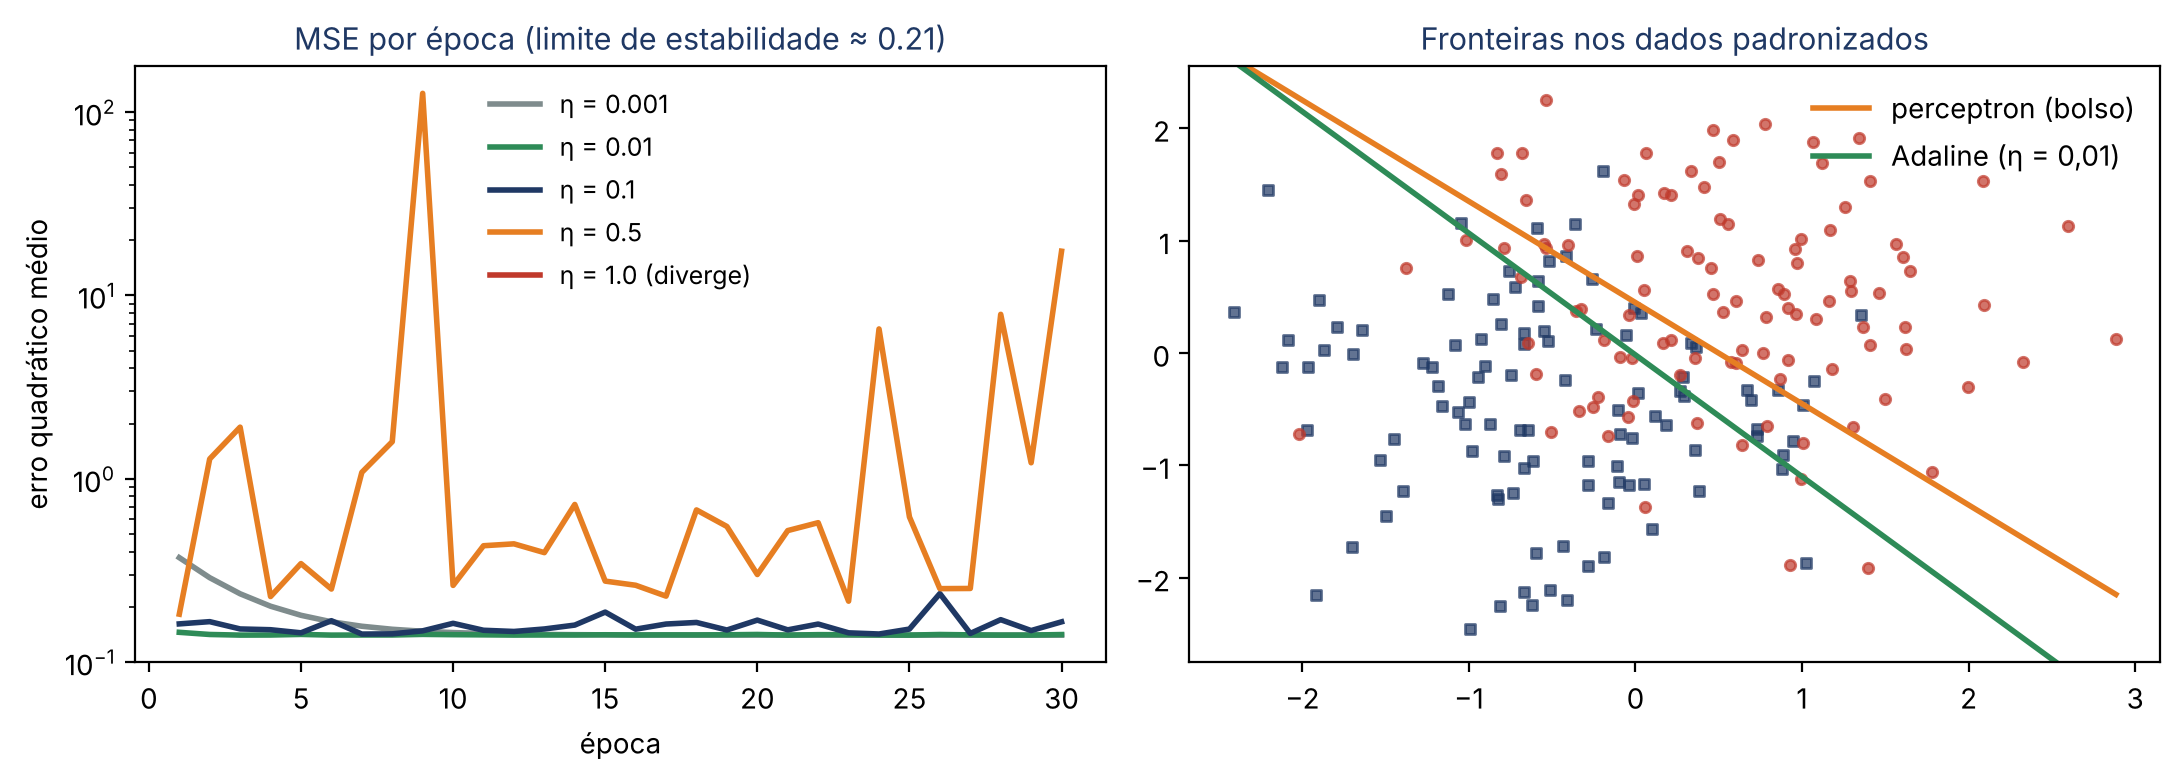

figura salva em lab_adaline_eta.png


In [6]:
class Adaline:
    def __init__(self, eta=0.01, max_epocas=50, embaralhar=True, semente=SEMENTE):
        self.eta, self.max_epocas, self.embaralhar, self.semente = eta, max_epocas, embaralhar, semente

    def z(self, X):
        return np.asarray(X, dtype=float) @ self.w + self.b

    def predict(self, X):
        return (self.z(X) >= 0.5).astype(int)          # alvos 0 e 1: limiar no ponto medio

    def score(self, X, t):
        return float(np.mean(self.predict(X) == np.asarray(t)))

    def fit(self, X, t):
        X, t = np.asarray(X, dtype=float), np.asarray(t, dtype=float)
        rng = np.random.default_rng(self.semente)
        self.w, self.b, self.mse_ = np.zeros(X.shape[1]), 0.0, []
        for _ in range(self.max_epocas):
            ordem = rng.permutation(len(X)) if self.embaralhar else np.arange(len(X))
            for i in ordem:
                e = t[i] - (X[i] @ self.w + self.b)        # erro REAL: t - z (sem o degrau)
                self.w = self.w + self.eta * e * X[i]
                self.b = self.b + self.eta * e
            self.mse_.append(float(np.mean((t - self.z(X)) ** 2)))
        return self


secao(5, "ADALINE: ERRO QUADRATICO E TAXA DE APRENDIZADO")
esc = StandardScaler().fit(X5tr)
A5tr, A5te = esc.transform(X5tr), esc.transform(X5te)
limite_eta = 2.0 / (np.sum(A5tr ** 2, axis=1) + 1).max()
print(f"limite de estabilidade 2 / max(||x||^2 + 1) = {limite_eta:.3f}")
linhas, curvas = [], {}
with np.errstate(all="ignore"):
    for eta in (0.001, 0.01, 0.1, 0.5, 1.0):
        a = Adaline(eta=eta, max_epocas=30).fit(A5tr, t5tr)
        curvas[eta] = a.mse_
        ok = np.isfinite(a.mse_[-1]) and a.mse_[-1] < 1e6
        linhas.append({"eta": eta, "MSE epoca 1": f"{a.mse_[0]:.3f}" if a.mse_[0] < 1e6 else "divergiu",
                       "MSE final": f"{a.mse_[-1]:.3f}" if ok else "divergiu",
                       "acuracia teste": f"{a.score(A5te, t5te):.3f}" if ok else "-"})
print(pd.DataFrame(linhas).to_string(index=False))
a01 = Adaline(eta=0.01, max_epocas=30).fit(A5tr, t5tr)
wb2, bb2, _ = perceptron_bolso(A5tr, t5tr)
print(f"teste: Adaline (eta = 0.01) {a01.score(A5te, t5te):.3f}   perceptron do bolso "
      f"{float(np.mean(((A5te @ wb2 + bb2) >= 0).astype(int) == t5te)):.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
cores = {0.001: CINZA, 0.01: VERDE, 0.1: AZUL, 0.5: LARANJA, 1.0: VERMELHO}
for eta, mse in curvas.items():
    y = np.array(mse); y[~np.isfinite(y) | (y > 1e3)] = np.nan
    rot = f"η = {eta}" + (" (diverge)" if np.all(np.isnan(y)) else "")
    a1.plot(range(1, len(y) + 1), y, c=cores[eta], lw=2, label=rot)
a1.set_yscale("log"); a1.set_xlabel("época"); a1.set_ylabel("erro quadrático médio")
a1.legend(frameon=False, fontsize=9)
a1.set_title(f"MSE por época (limite de estabilidade ≈ {limite_eta:.2f})", color=AZUL, fontsize=11)
a2.scatter(*A5tr[t5tr == 0].T, c=AZUL, marker="s", s=14, alpha=.7); a2.scatter(*A5tr[t5tr == 1].T, c=VERMELHO, marker="o", s=14, alpha=.7)
xs = np.linspace(A5tr[:, 0].min(), A5tr[:, 0].max(), 100)
a2.plot(xs, -(wb2[0] * xs + bb2) / wb2[1], "-", c=LARANJA, lw=2, label="perceptron (bolso)")
a2.plot(xs, (0.5 - a01.b - a01.w[0] * xs) / a01.w[1], "-", c=VERDE, lw=2, label="Adaline (η = 0,01)")
a2.set_ylim(A5tr[:, 1].min() - .3, A5tr[:, 1].max() + .3); a2.legend(frameon=False)
a2.set_title("Fronteiras nos dados padronizados", color=AZUL, fontsize=11)
fig.tight_layout()
salva(fig, "lab_adaline_eta.png")

## Passo 6 — a Iris: um par separável e um não separável
Setosa × versicolor é linearmente separável; versicolor × virginica não é. Os atributos são padronizados com média e desvio calculados **só no treino**, e o scikit-learn entra apenas como conferência.

In [7]:
secao(6, "IRIS: UM PAR SEPARAVEL E UM NAO SEPARAVEL")
iris = load_iris()


def par_iris(c0, c1):
    m = np.isin(iris.target, [c0, c1])
    X, t = iris.data[m], (iris.target[m] == c1).astype(int)
    Xtr, Xte, ttr, tte = train_test_split(X, t, test_size=0.3, random_state=SEMENTE, stratify=t)
    esc = StandardScaler().fit(Xtr)
    return esc.transform(Xtr), esc.transform(Xte), ttr, tte


Atr, Ate, ytr, yte = par_iris(0, 1)
p7 = Perceptron(eta=1.0, max_epocas=200, embaralhar=True).fit(Atr, ytr)
sk7 = PerceptronSklearn(eta0=1.0, tol=None, max_iter=200, random_state=SEMENTE).fit(Atr, ytr)
print("setosa x versicolor  convergiu?", p7.convergiu_, " epocas:", len(p7.erros_),
      " treino:", p7.score(Atr, ytr), " teste:", p7.score(Ate, yte), " sklearn (teste):", sk7.score(Ate, yte))
print("matriz de confusao (teste):\n", confusion_matrix(yte, p7.predict(Ate)))

Btr, Bte, ztr, zte = par_iris(1, 2)
p7b = Perceptron(eta=1.0, max_epocas=200, embaralhar=True).fit(Btr, ztr)
wb7, bb7, e_bolso7 = perceptron_bolso(Btr, ztr, max_epocas=200)
pred_bolso7 = ((Bte @ wb7 + bb7) >= 0).astype(int)
sk7b = PerceptronSklearn(eta0=1.0, tol=None, max_iter=200, random_state=SEMENTE).fit(Btr, ztr)
a7 = Adaline(eta=0.01, max_epocas=30).fit(Btr, ztr)
print("\nversicolor x virginica  convergiu?", p7b.convergiu_, " erros nas 5 ultimas epocas:", p7b.erros_[-5:])
print(f"teste: perceptron comum {p7b.score(Bte, zte):.3f}   bolso {np.mean(pred_bolso7 == zte):.3f}   "
      f"sklearn {sk7b.score(Bte, zte):.3f}   Adaline {a7.score(Bte, zte):.3f}   (erros do bolso no treino: {e_bolso7})")
print("matriz de confusao do bolso (teste):\n", confusion_matrix(zte, pred_bolso7))


PASSO 6 - IRIS: UM PAR SEPARAVEL E UM NAO SEPARAVEL
setosa x versicolor  convergiu? True  epocas: 2  treino: 1.0  teste: 1.0  sklearn (teste): 1.0
matriz de confusao (teste):
 [[15  0]
 [ 0 15]]

versicolor x virginica  convergiu? False  erros nas 5 ultimas epocas: [4, 3, 3, 3, 3]
teste: perceptron comum 0.900   bolso 0.900   sklearn 0.933   Adaline 0.967   (erros do bolso no treino: 1)
matriz de confusao do bolso (teste):
 [[14  1]
 [ 2 13]]
